<a href="https://colab.research.google.com/github/Patrick190508/whaleshark-mafia-island/blob/main/notebooks/LASSO_Ridge_All_Sites.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ridge and LASSO at all sites — Ningaloo, Donsol, Tofo, Gulf of Mexico
**Patrick Silingardi · Veritas AI Fellowship · Mentor: Samuel Haghshenas**

`LASSO_Ridge_Ningaloo.ipynb` tested the penalised logistic regression at Ningaloo only. This notebook applies the same procedure to every site that has a daily series, and compares the coefficients of the best Ridge and the best LASSO model between sites.

**Question.** Do the same environmental variables matter, with the same direction, at different aggregation sites?

**Process (same at every site).**
1. Peak season of the site, active seasons only (at least 20 sightings), days with all environmental values.
2. Target: `y = 1` if the day has more sightings than the mean of its season.
3. Split by whole seasons. Sites with 8 or more seasons: last 3 = test, 2 before = validation, the rest = training. Sites with 5 to 7 seasons: 2 training, 1 validation, the rest test.
4. Inputs standardised on the training seasons of the site.
5. Weekly baseline; Ridge and LASSO for 25 values of C; the best C is the one with the highest validation ROC-AUC (when two values tie, the stronger penalty is kept).
6. Test on the unseen seasons, used once.
7. Coefficients of the best Ridge and the best LASSO side by side, and whether each variable keeps the same sign at every site.

**Sites and inputs.** Ningaloo, Donsol (Philippines) and Tofo (Mozambique) have all 12 inputs. The Gulf of Mexico series has no wind and wave data, so it is run with a reduced set of 7 inputs (season, salinity, temperature, chlorophyll-a, moon) and is reported separately.

## 1. Functions

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

BASE = "https://raw.githubusercontent.com/Patrick190508/whaleshark-mafia-island/main/data/"
FULL = ["sday", "sday2", "sss", "sst", "sst2", "chl",
        "wind", "wind_3d", "wind2", "wave", "wave2", "moon_illum"]
REDUCED = ["sday", "sday2", "sss", "sst", "sst2", "chl", "moon_illum"]      # no wind / wave

# site: (file tag, peak months, inputs)
SITES = {"Ningaloo":       ("ningaloo",    [4, 5, 6],            FULL),
         "Donsol":         ("philippines", [2, 3, 4, 5],         FULL),
         "Tofo":           ("mozambique",  [10, 11, 12, 1, 2],   FULL),
         "Gulf of Mexico": ("gulf",        [6, 7, 8, 9],         REDUCED)}
MIN_SIGHTINGS = 20
Cs = np.logspace(-3, 2, 25)
NEW_API = tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 8)

def make_logit(kind, C=1.0):
    """'ridge' (L2) or 'lasso' (L1). Small C = strong penalty."""
    if kind == "ridge":
        return (LogisticRegression(C=C, l1_ratio=0, max_iter=5000) if NEW_API
                else LogisticRegression(penalty="l2", C=C, max_iter=5000))
    return (LogisticRegression(C=C, l1_ratio=1, solver="liblinear", max_iter=5000, random_state=0) if NEW_API
            else LogisticRegression(penalty="l1", C=C, solver="liblinear", max_iter=5000, random_state=0))

def build_site(tag, peak):
    s = pd.read_csv(BASE + f"daily_{tag}.csv", parse_dates=["date"])
    if "moon_illum" not in s:                      # same formula as the other sites
        moon = ((s["date"] - pd.Timestamp("2000-01-06")).dt.days % 29.53) / 29.53
        s["moon_illum"] = (1 - np.cos(2 * np.pi * moon)) / 2
    s = s[s["month"].isin(peak)].copy()
    wraps = peak[0] > peak[-1]                     # season crossing New Year
    s["season"] = np.where(wraps & (s["month"] < peak[0]), s["year"] - 1, s["year"])
    s = s.sort_values("date")
    s["sday"] = s.groupby("season").cumcount() + 1
    s["week"] = (s["sday"] - 1) // 7 + 1
    tot = s.groupby("season")["sightings"].sum()
    s = s[s["season"].isin(tot[tot >= MIN_SIGHTINGS].index)]
    s = s.dropna(subset=[c for c in ["sst", "chl", "sss", "wind", "wave"] if c in s]).copy()
    for c in ["sday", "sst", "wave", "wind"]:
        if c in s: s[c + "2"] = s[c] ** 2
    s["y"] = (s["sightings"] > s.groupby("season")["sightings"].transform("mean")).astype(int)
    se = sorted(int(x) for x in s["season"].unique())
    if len(se) >= 8:   split = {"train": se[:-5], "val": se[-5:-3], "test": se[-3:]}
    elif len(se) >= 5: split = {"train": se[:2],  "val": se[2:3],   "test": se[3:]}
    else: return None, se
    return {k: s[s["season"].isin(v)] for k, v in split.items()}, split

def auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(p)) > 1 else 0.5

def run_site(name):
    tag, peak, feats = SITES[name]
    parts, split = build_site(tag, peak)
    tr, va, te = parts["train"], parts["val"], parts["test"]
    sc = StandardScaler().fit(tr[feats])
    Xtr, Xva, Xte = (sc.transform(p[feats]) for p in (tr, va, te))
    wk = tr.groupby("week")["y"].mean()
    base = lambda d: d["week"].map(wk).fillna(tr["y"].mean()).values
    info = {"site": name, "inputs": len(feats),
            "train seasons": f"{split['train'][0]}–{split['train'][-1]}", "val seasons": ", ".join(map(str, split["val"])),
            "test seasons": ", ".join(map(str, split["test"])),
            "days train/val/test": f"{len(tr)}/{len(va)}/{len(te)}",
            "good days (test)": round(te["y"].mean(), 2)}
    res = {"baseline": {"C": np.nan, "val": auc(va["y"], base(va)), "test": auc(te["y"], base(te)), "kept": 0}}
    coefs, curves = {}, {}
    for kind in ["ridge", "lasso"]:
        rows = []
        for c in Cs:
            m = make_logit(kind, c).fit(Xtr, tr["y"])
            rows.append({"C": c, "val": auc(va["y"], m.predict_proba(Xva)[:, 1]),
                         "kept": int((np.abs(m.coef_[0]) > 1e-8).sum())})
        g = pd.DataFrame(rows); curves[kind] = g
        best = g.sort_values(["val", "C"], ascending=[False, True]).iloc[0]   # tie -> stronger penalty
        m = make_logit(kind, best.C).fit(Xtr, tr["y"])
        res[kind] = {"C": best.C, "val": best.val, "kept": int(best.kept),
                     "test": auc(te["y"], m.predict_proba(Xte)[:, 1])}
        coefs[kind] = pd.Series(m.coef_[0], index=feats)
    m = make_logit("ridge", 1.0).fit(Xtr, tr["y"])
    res["ridge C=1 (report)"] = {"C": 1.0, "val": auc(va["y"], m.predict_proba(Xva)[:, 1]),
                                 "test": auc(te["y"], m.predict_proba(Xte)[:, 1]), "kept": len(feats)}
    return info, res, coefs, curves

out = {name: run_site(name) for name in SITES}
print("done:", list(out))

done: ['Ningaloo', 'Donsol', 'Tofo', 'Gulf of Mexico']


## 2. Data available at each site

In [2]:
pd.DataFrame([out[s][0] for s in SITES]).set_index("site")

,inputs,train seasons,val seasons,test seasons,days train/val/test,good days (test)
site,,,,,,
Ningaloo,12,1998–2004,"2005, 2006","2007, 2008, 2009",637/182/273,0.42
Donsol,12,2006–2007,2008,"2009, 2010",240/121/240,0.32
Tofo,12,2005–2006,2007,"2008, 2009",292/152/302,0.14
Gulf of Mexico,7,2004–2007,"2008, 2009","2017, 2019, 2025",488/244/366,0.14


## 3. Choice of the penalty at each site
Validation ROC-AUC for each value of C (solid = Ridge, dashed = LASSO), with the weekly baseline as a dotted line.

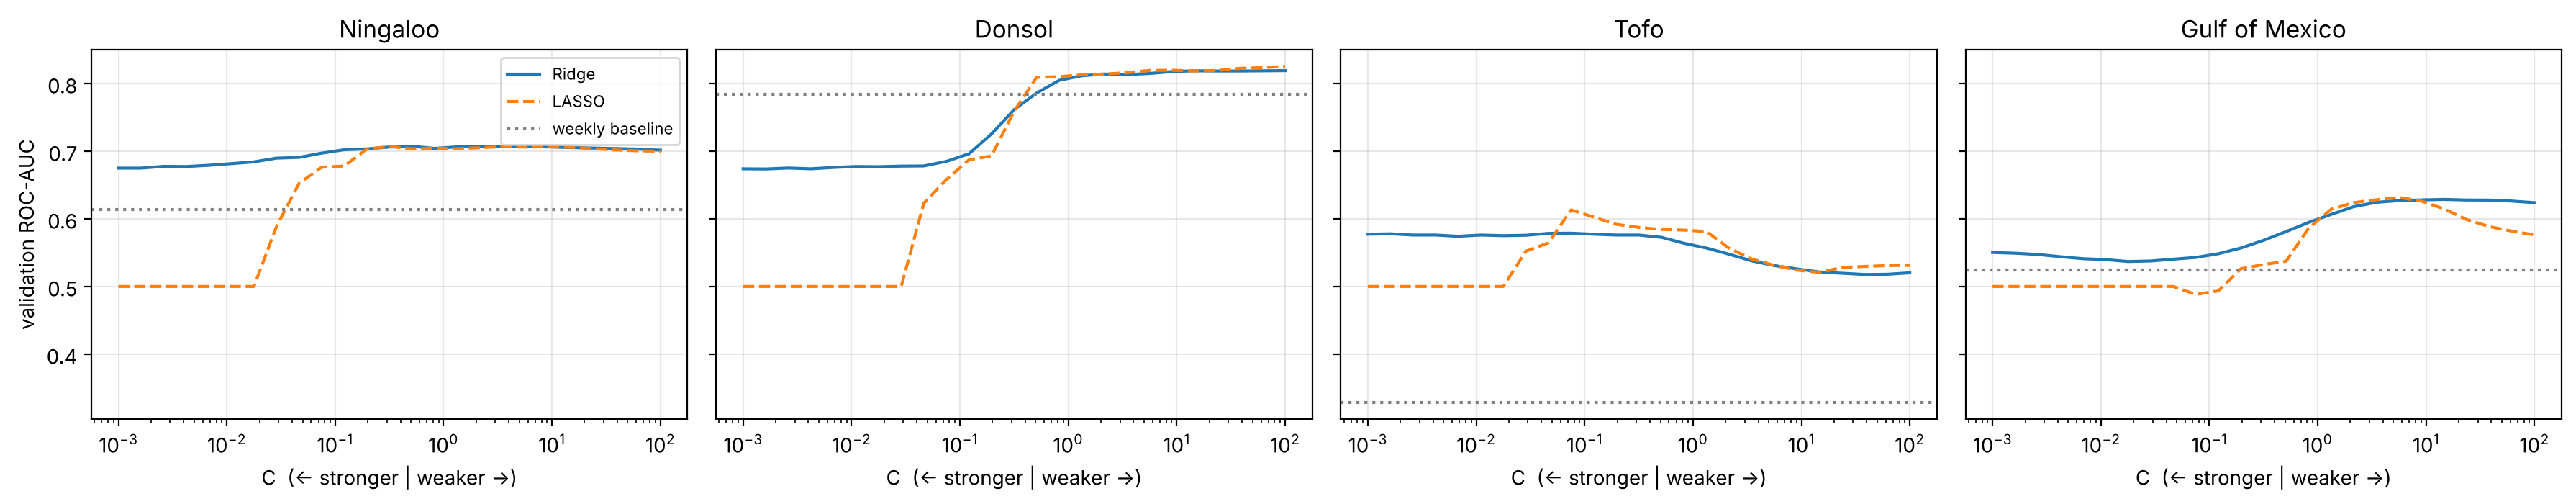

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, name in zip(axes, SITES):
    _, res, _, curves = out[name]
    ax.plot(curves["ridge"]["C"], curves["ridge"]["val"], "-", color="tab:blue", label="Ridge")
    ax.plot(curves["lasso"]["C"], curves["lasso"]["val"], "--", color="tab:orange", label="LASSO")
    ax.axhline(res["baseline"]["val"], color="grey", ls=":", label="weekly baseline")
    ax.set_xscale("log"); ax.set_title(name); ax.set_xlabel("C  (← stronger | weaker →)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("validation ROC-AUC"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("penalty_all_sites.png", dpi=200); plt.show()

## 4. Results on the unseen test seasons

In [4]:
rows = []
for name in SITES:
    _, res, _, _ = out[name]
    for model, r in res.items():
        rows.append({"site": name, "model": model, "C": r["C"], "variables kept": r["kept"] or "",
                     "val ROC-AUC": r["val"], "test ROC-AUC": r["test"]})
results = pd.DataFrame(rows).set_index(["site", "model"])
results.to_csv("results_all_sites.csv")
results.round(3)

C variables kept  val ROC-AUC  \
site           model                                                     
Ningaloo       baseline                NaN                       0.614   
               ridge                 5.623             12        0.707   
               lasso                 0.316              9        0.707   
               ridge C=1 (report)    1.000             12        0.705   
Donsol         baseline                NaN                       0.784   
               ridge               100.000             12        0.819   
               lasso               100.000             12        0.825   
               ridge C=1 (report)    1.000             12        0.808   
Tofo           baseline                NaN                       0.329   
               ridge                 0.075             12        0.579   
               lasso                 0.075              4        0.613   
               ridge C=1 (report)    1.000             12        0.563   
Gulf of Mexico baseline                NaN                       0.525   
               ridge                14.678              7        0.629   
               lasso                 5.623              6        0.632   
               ridge C=1 (report)    1.000              7        0.599   

                                   test ROC-AUC  
site           model                             
Ningaloo       baseline                   0.573  
               ridge                      0.641  
               lasso                      0.637  
               ridge C=1 (report)         0.638  
Donsol         baseline                   0.435  
               ridge                      0.512  
               lasso                      0.514  
               ridge C=1 (report)         0.524  
Tofo           baseline                   0.507  
               ridge                      0.611  
               lasso                      0.602  
               ridge C=1 (report)         0.601  
Gulf of Mexico baseline                   0.532  
               ridge                      0.605  
               lasso                      0.610  
               ridge C=1 (report)         0.578

## 5. Coefficients of the best Ridge and the best LASSO, site by site
Inputs are standardised at each site, so sign = direction and size = weight inside the model of that site. A zero in a LASSO column means that the variable was removed.

In [5]:
full_sites = [s for s in SITES if SITES[s][2] == FULL]
ridge = pd.DataFrame({s: out[s][2]["ridge"] for s in full_sites})
lasso = pd.DataFrame({s: out[s][2]["lasso"] for s in full_sites})

def same_sign(df):
    sg = np.sign(df.where(df.abs() > 1e-8))          # ignore zeros
    return sg.nunique(axis=1).le(1) & sg.notna().all(axis=1)

ridge_t = ridge.round(2).assign(**{"same sign at all sites": same_sign(ridge)})
lasso_t = lasso.round(2).assign(**{"kept at": (lasso.abs() > 1e-8).sum(axis=1).astype(str) + " of 3",
                                   "same sign where kept": np.sign(lasso.where(lasso.abs() > 1e-8)).nunique(axis=1).le(1)})
print("Best Ridge per site"); display(ridge_t)
print("Best LASSO per site"); display(lasso_t)
ridge.to_csv("coefs_ridge.csv"); lasso.to_csv("coefs_lasso.csv")

Best Ridge per site


,Ningaloo,Donsol,Tofo,same sign at all sites
sday,1.66,5.76,0.07,True
sday2,-2.00,-5.78,-0.06,True
sss,0.14,0.21,0.27,True
sst,0.50,5.43,-0.10,False
sst2,-0.60,-4.64,-0.13,True
chl,0.19,-0.61,-0.23,False
wind,0.60,2.20,-0.22,False
wind_3d,-0.36,-0.36,-0.06,True
wind2,-0.50,-2.93,-0.30,True
wave,0.42,1.82,-0.13,False


Best LASSO per site


,Ningaloo,Donsol,Tofo,kept at,same sign where kept
sday,0.89,3.73,0.00,2 of 3,True
sday2,-1.12,-4.00,0.00,2 of 3,True
sss,0.09,0.25,0.16,3 of 3,True
sst,0.00,32.34,0.00,1 of 3,True
sst2,-0.03,-31.32,0.00,2 of 3,True
chl,0.15,-0.64,-0.01,3 of 3,False
wind,0.02,1.89,0.00,2 of 3,True
wind_3d,-0.22,-0.45,0.00,2 of 3,True
wind2,0.00,-2.67,-0.38,2 of 3,True
wave,0.00,2.32,-0.06,2 of 3,False


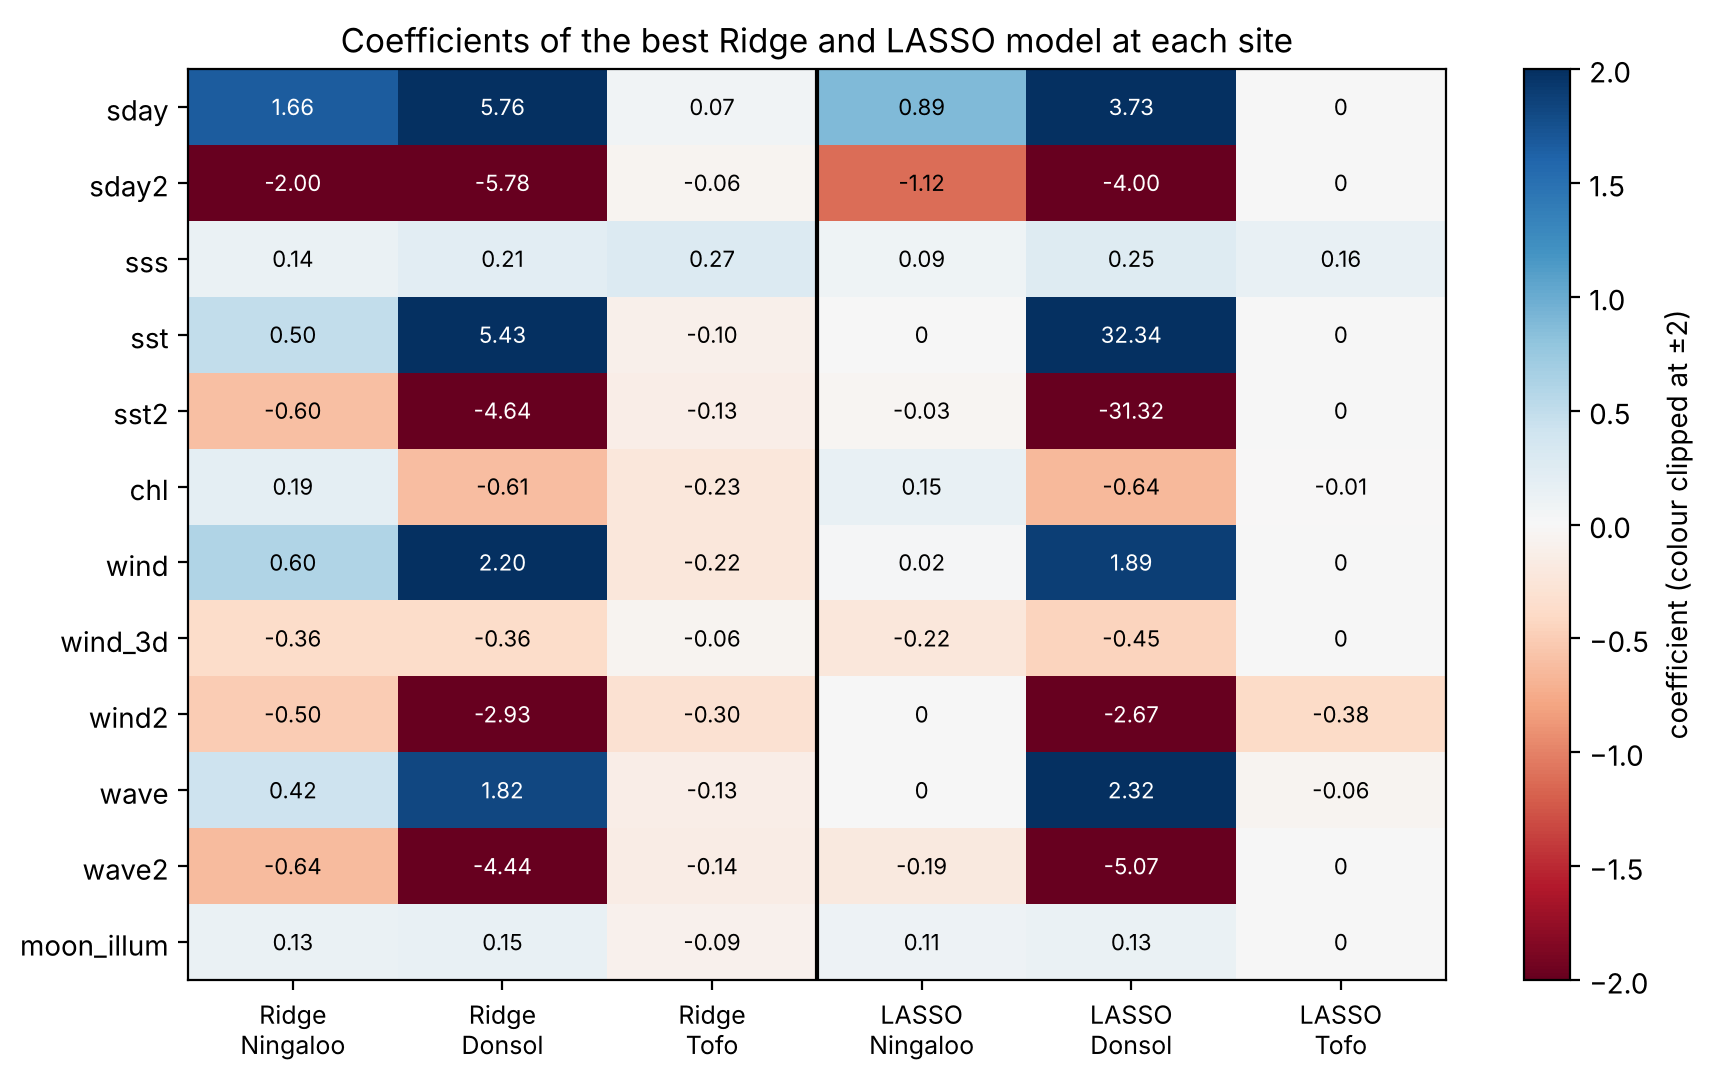

In [6]:
# one picture: rows = variables, columns = site x model; colour = sign and size (clipped at ±2)
both = pd.concat({"Ridge": ridge, "LASSO": lasso}, axis=1)
fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(both.clip(-2, 2).values, cmap="RdBu", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(both.shape[1])); ax.set_xticklabels([f"{m}\n{s}" for m, s in both.columns], fontsize=9)
ax.set_yticks(range(len(both))); ax.set_yticklabels(both.index)
for i in range(both.shape[0]):
    for j in range(both.shape[1]):
        v = both.values[i, j]
        ax.text(j, i, "0" if abs(v) < 1e-8 else f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 1.2 else "black")
ax.axvline(2.5, color="k", lw=1.5)
plt.colorbar(im, label="coefficient (colour clipped at ±2)")
ax.set_title("Coefficients of the best Ridge and LASSO model at each site")
plt.tight_layout(); plt.savefig("coefficients_all_sites.png", dpi=220); plt.show()

### Gulf of Mexico (reduced set of inputs)

In [7]:
g = pd.DataFrame({"Ridge": out["Gulf of Mexico"][2]["ridge"], "LASSO": out["Gulf of Mexico"][2]["lasso"]})
g.round(2)

,Ridge,LASSO
sday,1.61,1.58
sday2,-1.71,-1.68
sss,0.03,0.02
sst,1.69,0.00
sst2,-1.83,-0.14
chl,0.07,0.07
moon_illum,-0.31,-0.30


## 6. Results

**Prediction.** At every site the penalised logistic regression has a higher ROC-AUC than the weekly baseline on seasons it has never seen: Ningaloo 0.64 against 0.57, Tofo 0.61 (Ridge) and 0.60 (LASSO) against 0.51, Gulf of Mexico 0.61 against 0.53 (reduced inputs), Donsol 0.51 against 0.44. The gain is between 0.07 and 0.10 everywhere, but at Donsol both scores are at the level of chance (0.5), so that site gives no usable prediction.

**Penalty.** Only Ningaloo has a stable choice of C (the validation curve is flat above C ≈ 0.2). At Donsol the best validation score is at the weakest penalty (C = 100, nothing removed), and the validation score (0.82) does not carry over to the test seasons (0.51): one validation season is not enough to choose a penalty. At Tofo the best C is small (0.075) and LASSO keeps 4 variables of 12.

**Coefficients, Ridge.** Seven of the twelve coefficients have the same sign at the three sites with all inputs: day of season (+) and its square (−), salinity (+), temperature² (−), 3-day wind (−), wind² (−) and wave² (−). Temperature, chlorophyll-a, moon illumination and the linear wind and wave terms change sign between sites.

**Coefficients, LASSO.** Salinity is the only variable kept at all three sites with the same sign. Where they are kept, 3-day wind, wind² and wave² are always negative. Chlorophyll-a is positive at Ningaloo and negative at Donsol. At Tofo, LASSO removes the season terms, which agrees with the weak seasonality of that site in the monthly table.

**Donsol coefficients.** The very large temperature coefficients (+32 and −31 in LASSO) are not an effect of temperature: with two training seasons and almost no penalty, temperature and its square carry nearly the same information and their coefficients cancel each other.

## 7. Discussion

- The part of the model that repeats at every site is the one linked to sea state: more wind over the previous three days, strong wind and high waves all lower the chance of a better-than-average day. This agrees with Rohner et al. (2013), who found wave height among the predictors of sightings at Tofo.
- The data cannot say whether this is behaviour (sharks leave the surface) or observation (boats go out less and see less in rough sea), because there is no measure of search effort.
- Temperature and chlorophyll-a do not have a consistent direction between sites, so no general statement can be made about them from these data.
- Only Ningaloo (12 seasons) supports a firm result. Donsol and Tofo have five seasons each and the Gulf of Mexico has few sightings per season and no wind or wave data; their results are indications, not conclusions.